In [7]:
import glob
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [8]:
pattern = (9, 6)
objp = np.zeros((pattern[0] * pattern[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern[0], 0:pattern[1]].T.reshape(-1, 2)

obj_points, img_points = [], []
paths = sorted(glob.glob('calib/*.jpg'))
for path in paths:
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ok, corners = cv2.findChessboardCorners(gray, pattern)
    if not ok:
        print('no corners in', path)
        continue
    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))
    obj_points.append(objp)
    img_points.append(corners)

len(paths), len(obj_points)

(12, 12)

In [9]:
# calibrate
size = gray.shape[::-1]
rms, K, dist, _, _ = cv2.calibrateCamera(obj_points, img_points, size, None, None)

os.makedirs('output', exist_ok=True)
np.savez('output/calibration.npz', K=K, dist=dist, size=size)

print('rms reprojection error:', rms)
print('camera matrix:\n', K)
print('distortion:', dist.ravel())

rms reprojection error: 0.4222752995206221
camera matrix:
 [[536.41467432   0.         342.05702215]
 [  0.         536.37786415 235.94063833]
 [  0.           0.           1.        ]]
distortion: [-0.26577055 -0.04214773  0.00196878 -0.00031946  0.24274738]


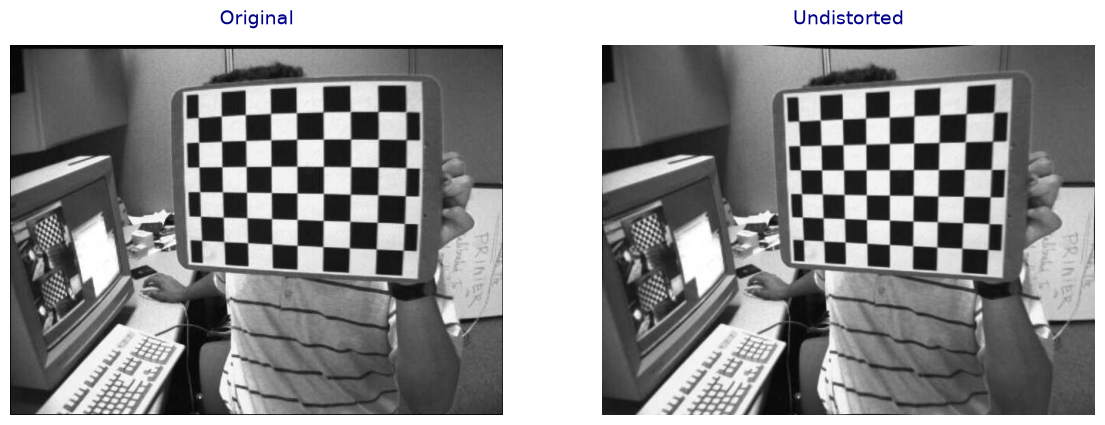

In [10]:
# check
test = cv2.imread(paths[0], cv2.IMREAD_COLOR_RGB)
h, w = test.shape[:2]
newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
fixed = cv2.undistort(test, K, dist, None, newK)

panels = [('Original', test), ('Undistorted', fixed)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [11]:
# live feed (q or close to stop)
data = np.load('output/calibration.npz')
K, dist = data['K'], data['dist']

cap = cv2.VideoCapture(0)
print('webcam opened:', cap.isOpened())

title = 'original | undistorted'
newK = None
sample = None
try:
    while cap.isOpened():
        ok, frame = cap.read()
        if not ok:
            break
        if newK is None:
            h, w = frame.shape[:2]
            newK, _ = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
        fixed = cv2.undistort(frame, K, dist, None, newK)
        sample = (frame, fixed)
        cv2.imshow(title, np.hstack([frame, fixed]))
        key = cv2.waitKey(1) & 0xFF
        if key == ord('q') or cv2.getWindowProperty(title, cv2.WND_PROP_VISIBLE) < 1:
            break
finally:
    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)

webcam opened: True


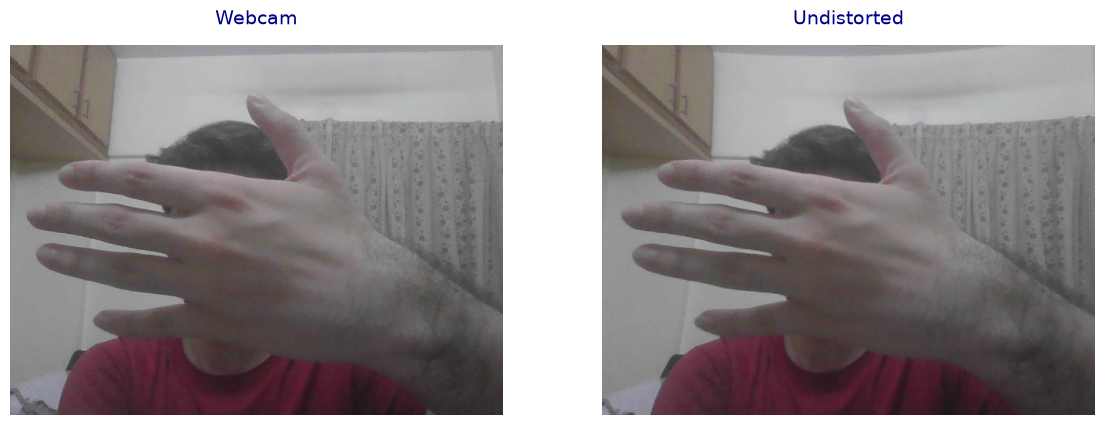

In [12]:
panels = [
    ('Webcam', cv2.cvtColor(sample[0], cv2.COLOR_BGR2RGB)),
    ('Undistorted', cv2.cvtColor(sample[1], cv2.COLOR_BGR2RGB)),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()